In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
import pandas as pd

Dataset shape: 569 rows x 31 columns

Diagnosis counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Missing values: 0


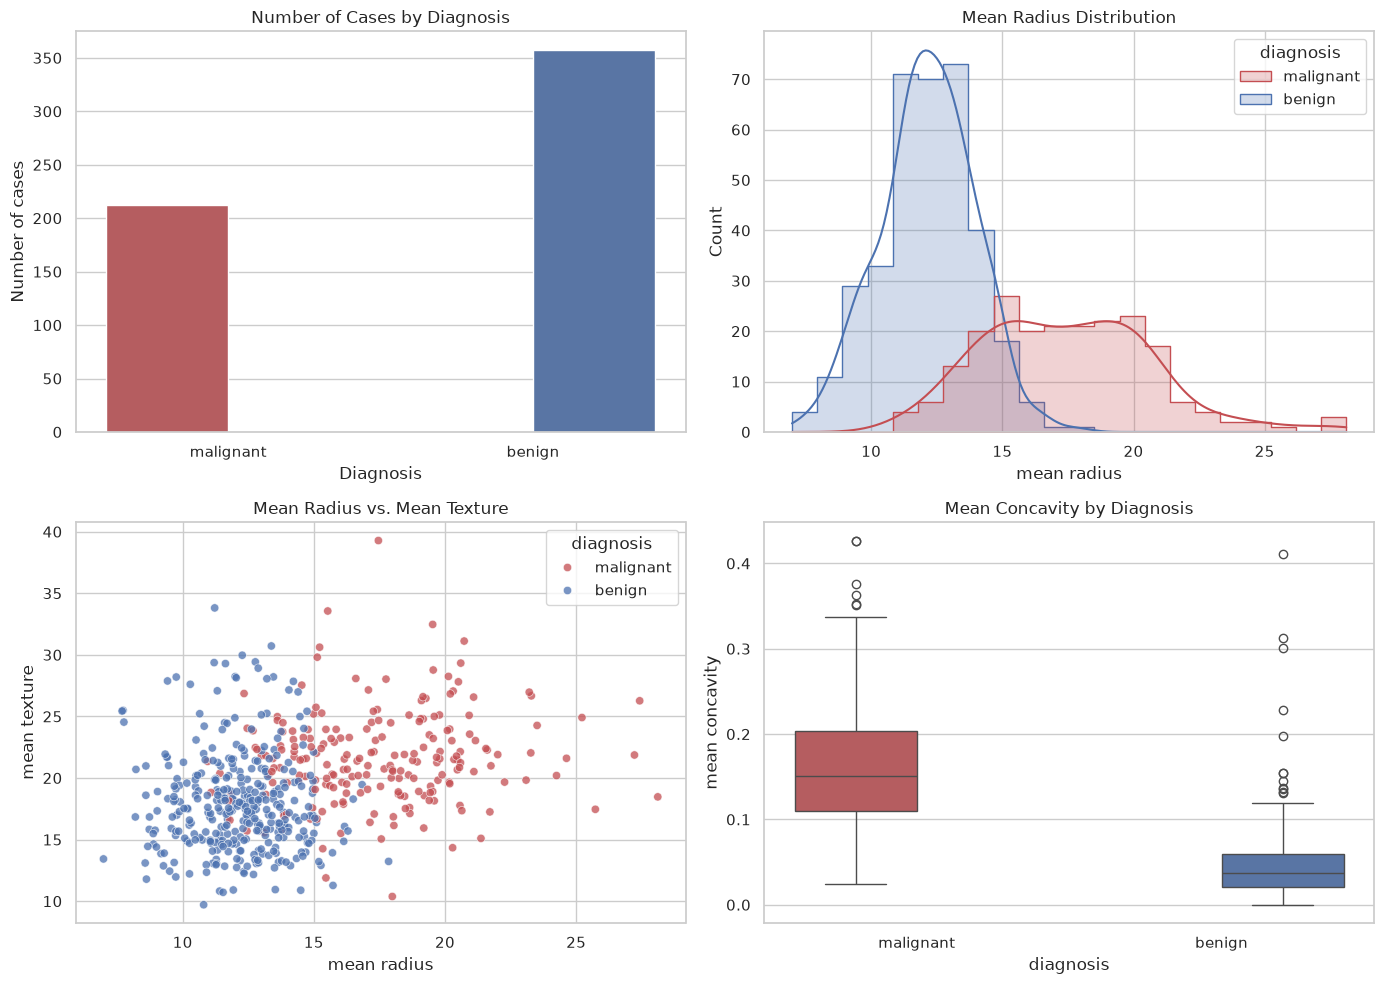

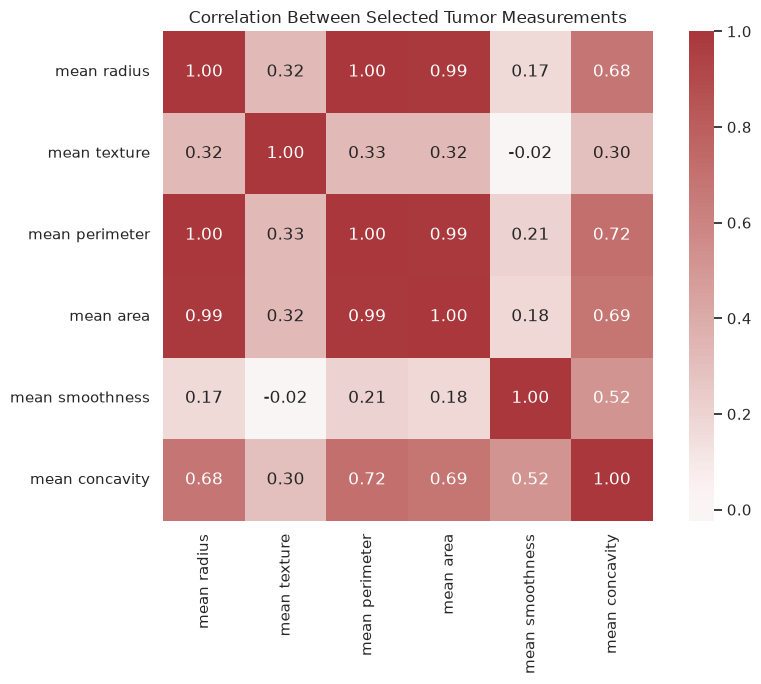

In [2]:
cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df["diagnosis"] = pd.Categorical.from_codes(cancer.target, cancer.target_names)

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())
print("\nMissing values:", df.isna().sum().sum())

diagnosis_colors = {"malignant": "#c44e52", "benign": "#4c72b0"}
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=diagnosis_colors, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Number of Cases by Diagnosis")
axes[0, 0].set_xlabel("Diagnosis")
axes[0, 0].set_ylabel("Number of cases")

sns.histplot(data=df, x="mean radius", hue="diagnosis", palette=diagnosis_colors, kde=True, element="step", ax=axes[0, 1])
axes[0, 1].set_title("Mean Radius Distribution")

sns.scatterplot(data=df, x="mean radius", y="mean texture", hue="diagnosis", palette=diagnosis_colors, alpha=0.75, ax=axes[1, 0])
axes[1, 0].set_title("Mean Radius vs. Mean Texture")

sns.boxplot(data=df, x="diagnosis", y="mean concavity", hue="diagnosis", palette=diagnosis_colors, legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Mean Concavity by Diagnosis")

fig.tight_layout()
plt.show()

correlation_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean concavity"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[correlation_features].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation Between Selected Tumor Measurements")
plt.tight_layout()
plt.show()

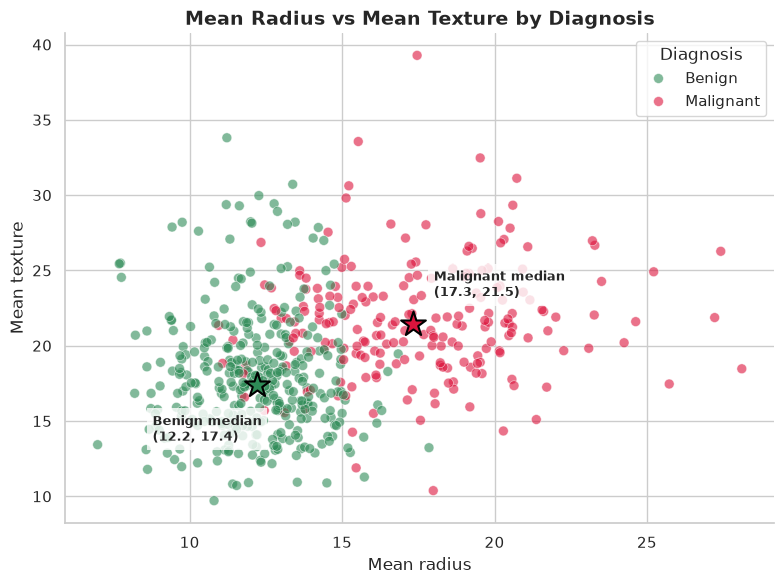

Pearson correlation (radius vs texture): 0.32


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['diagnosis'] = data.target
df['diagnosis_label'] = df['diagnosis'].map({0: 'Malignant', 1: 'Benign'})
palette = {'Malignant': 'crimson', 'Benign': 'seagreen'}

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x='mean radius', y='mean texture',
                hue='diagnosis_label', hue_order=['Benign', 'Malignant'],
                palette=palette, alpha=0.6, s=50,
                edgecolor='white', linewidth=0.5, ax=ax)

# Star markers show the median of each group (medians are robust to outliers)
medians = df.groupby('diagnosis_label')[['mean radius', 'mean texture']].median()
offsets = {'Benign': (-75, -40), 'Malignant': (15, 20)}
for label, row in medians.iterrows():
    ax.scatter(row['mean radius'], row['mean texture'], marker='*', s=350,
               color=palette[label], edgecolor='black', linewidth=1.5, zorder=5)
    ax.annotate(f"{label} median\n({row['mean radius']:.1f}, {row['mean texture']:.1f})",
                (row['mean radius'], row['mean texture']),
                xytext=offsets[label], textcoords='offset points',
                fontsize=9, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_title('Mean Radius vs Mean Texture by Diagnosis', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean radius')
ax.set_ylabel('Mean texture')
ax.legend(title='Diagnosis')
sns.despine()
plt.tight_layout()
plt.show()

r = df['mean radius'].corr(df['mean texture'])
print(f"Pearson correlation (radius vs texture): {r:.2f}")